# Cattle Replacement-Heifer Selection — Notebook/Report

**Course:** ML Foundations — IE University, May 2026

**Team:** Tatiana Quinn, Hari Siva, Alesia Dako, Viktoriia Stepanenko, Kohana Rakipi & Laura Somogyi

**GitHub repository:** https://github.com/TatianaQuinnIE/cattle-heifer-selection

## Project framing

The farm faces an annual decision: which female calves to keep as future mothers and which to sell. We are testing whether a data-driven model can refine the existing hand-coded rule.

We structure the analysis in three layers:

1. **Outcome prediction** — supervised regression on mean future IHM (Maternal Ability Index)
2. **Rule analysis** — programmatic reproduction of the farm's documented rule and concept-drift quantification
3. **Rule-vs-outcome comparison** — where rule and model disagree, which matches reality?

## Reproducibility

Every cell runs top-to-bottom. The pipeline reads from `data/raw/` and writes intermediate artifacts to `data/processed/` and `outputs/`. Re-running this notebook reproduces every figure and number we report.

## 1. Setup

In [1]:
import os
from pathlib import Path
import sys

if Path.cwd().name == "notebooks":
    os.chdir("..")

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

print("Working directory:", ROOT)
print("src exists:", (ROOT / "src").exists())

Working directory: /Users/tatianaquinn/Desktop/cattle-heifer-selection
src exists: True


In [2]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)

ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT))
print(f'Project root: {ROOT}')

Project root: /Users/tatianaquinn/Desktop/cattle-heifer-selection


## 2. Load and reconcile the source data

The farm provided four Excel files plus 40+ CSV exports from DataMars covering the reproductive cycles. Each source presented different inconsistencies, including variations in IDV capitalization, two label schemes that evolved over years, IHM stored as percent in one file and proportion in another, mojibake in some headers, and a free-text WhatsApp alarm log.

The `load.py` module imports each dataset in its original form, while `clean.py` standardizes IDs, labels, and IHM scales. Finally, lineage.py reconciles all sources into a unified cow-level registry.

In [3]:
from src.load import load_all_sources
from src.lineage import build_cow_registry, build_lineage_table, lineage_summary

sources = load_all_sources(ROOT / 'data' / 'raw')
for k, v in sources.items():
    if hasattr(v, 'shape'):
        print(f'{k:25s} {v.shape}')
    else:
        print(f'{k:25s} text, {len(v)} chars')

historial_ihm_old         (822, 22)
ihm_historico_new         (1208, 18)
terneras_2027             (405, 28)
fm_prep_2025              (364, 21)
vientres                  (881, 17)
terneros_sesiones         (726, 14)
nacimientos_2025          (800, 14)
base_madres               (792, 37)
peso_terneros_2027        (757, 4)
iatf_sessions             (696, 45)
whatsapp_raw              text, 5645 chars


In [4]:
registry = build_cow_registry(sources)
lineage  = build_lineage_table(registry)

summary = lineage_summary(registry, lineage)
for k, v in summary.items():
    print(f'{k:30s} {v}')

total_cows                     2728
with_mother_idv                1733
mother_in_registry             1610
with_grandmother_idv           422
with_sire_name                 2236
with_maternal_grandsire        1607


**2,728 unique cows reconciled.** 64% have a known mother IDV; of those, 93% chain back into the registry, giving us 2-generation lineage for most of the herd.

## 3. IHM history and reproductive cycles

Two main outcome data sources:
- **IHM (Maternal Ability Index)** measures milk transfer to the calf. Recorded annually 2022–2026 in our data.
- **Reproductive cycles** (insemination → ecografía → tacto): which cows successfully gestated each year, and at what stage. Recorded across 6 breeding years (2020–2025) and 3 session kinds (IATF insemination, ecografía/pregnancy ultrasound, tacto/palpation).

In [5]:
from src.features import build_ihm_history, compute_future_ihm
from src.reproduction import build_reproduction_events, build_reproduction_outcomes

ihm_history = build_ihm_history(sources)
events      = build_reproduction_events(ROOT / 'data' / 'raw')
outcomes    = build_reproduction_outcomes(events)

print(f'IHM history:           {len(ihm_history)} cow-year observations')
print(f'Reproductive events:   {len(events)} (across {events["session_kind"].nunique()} session kinds)')
print(f'Cycle outcomes:        {len(outcomes)} cow-year reproductive records')
print(f'\nReproductive year coverage:')
print(outcomes['breeding_year'].value_counts().sort_index().to_string())

IHM history:           5265 cow-year observations
Reproductive events:   13835 (across 3 session kinds)
Cycle outcomes:        5305 cow-year reproductive records

Reproductive year coverage:
breeding_year
2020    862
2021    957
2022    852
2023    852
2024    871
2025    911


Cows with adult-IHM outcomes: 343
  with 2+ adult years observed:  153
  with 3+ adult years observed:  26


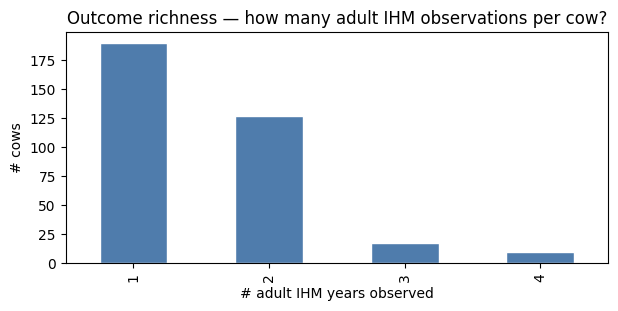

In [6]:
future_outcomes = compute_future_ihm(ihm_history, registry)
print(f'Cows with adult-IHM outcomes: {len(future_outcomes)}')
print(f'  with 2+ adult years observed:  {(future_outcomes["n_outcome_years"] >= 2).sum()}')
print(f'  with 3+ adult years observed:  {(future_outcomes["n_outcome_years"] >= 3).sum()}')

future_outcomes['n_outcome_years'].value_counts().sort_index().plot.bar(
    color='#4F7CAC', edgecolor='white', figsize=(7, 3))
plt.xlabel('# adult IHM years observed')
plt.ylabel('# cows')
plt.title('Outcome richness — how many adult IHM observations per cow?')
plt.show()

## 4. The supervised dataset

Each row represents one cow and includes only features that would have been available at the time of selection, such as the mother's IHM history, sire info, cohort, pelaje and her future-IHM outcome. The analysis is restricted to cows born 2017–2022 the period for which both selection-time features and later adult outcomes are available. Strict leakage control is applied throughout the pipeline, meaning no feature uses information that would have been unavailable at the moment of the heifer's hypothetical selection.

We also include reproductive-cycle features:
- **Mother's reproductive history** (leakage-safe, pre-selection only)
- **Cow's own reproductive history** (used as a secondary outcome and for the composite target)

The most non-trivial piece of feature engineering is the temporal construction of the sire averages: for each heifer, sire_mean_daughter_ihm_prior includes only the IHM observations of her half-sisters whose adult IHM was recorded before her own selection year. This guarantees the feature could have been computed at the moment of selection, and is the principal piece of substantive (not just preprocessing) feature engineering in the pipeline.

In [7]:
from src.supervised_v2 import build_supervised_dataset_v2, supervised_summary

ds = build_supervised_dataset_v2(
    sources, registry, ihm_history, ROOT / 'data' / 'raw',
    min_birth_year=2017, max_birth_year=2022
)

for k, v in supervised_summary(ds).items():
    print(f'{k:30s} {v}')

total_rows                     452
with_ihm_outcome               337
with_repro_outcome             424
with_both_outcomes             312
with_composite_outcome         312
with_mother_ihm_pre            136
with_mother_repro_pre          151


In [8]:
# Outlier and data quality check on the supervised population
supervised = ds[ds['mean_future_ihm'].notna()].copy()

print('=== Feature range checks (supervised population, n=%d) ===' % len(supervised))
for col in ['peso_al_nacer', 'mean_future_ihm', 'madre_mean_ihm_pre', 'madre_max_ihm_pre']:
    if col not in supervised.columns:
        continue
    s = supervised[col].dropna()
    q01, q99 = s.quantile(0.01), s.quantile(0.99)
    n_extreme = int(((s < q01) | (s > q99)).sum())
    print(f'  {col:30s}: min={s.min():.3f}, max={s.max():.3f}, '
          f'p1={q01:.3f}, p99={q99:.3f}, n_p1_p99_tail={n_extreme}')

if 'peso_al_nacer' in supervised.columns:
    extremes = supervised[supervised['peso_al_nacer'] > 60][['idv', 'anio_nacimiento', 'peso_al_nacer']]
    if len(extremes):
        print(f'\nBirth weight > 60 kg (likely data-entry errors): n={len(extremes)}')
        print(extremes.to_string(index=False))
    else:
        print('\nNo extreme birth weights (>60 kg) detected.')

print('\nHandling strategy: sklearn Pipelines use median imputation for missing values;'
      ' extreme values are kept as-is (tree models are scale-invariant and outlier-robust).')

=== Feature range checks (supervised population, n=337) ===
  peso_al_nacer                 : min=30.000, max=30.000, p1=30.000, p99=30.000, n_p1_p99_tail=0
  mean_future_ihm               : min=0.170, max=0.560, p1=0.257, p99=0.550, n_p1_p99_tail=7
  madre_mean_ihm_pre            : min=0.343, max=0.602, p1=0.353, p99=0.596, n_p1_p99_tail=2
  madre_max_ihm_pre             : min=0.343, max=0.620, p1=0.359, p99=0.602, n_p1_p99_tail=2

No extreme birth weights (>60 kg) detected.

Handling strategy: sklearn Pipelines use median imputation for missing values; extreme values are kept as-is (tree models are scale-invariant and outlier-robust).


**337 cows form our trainable population**, of which 309 also have reproductive outcomes.

An important empirical finding is that IHM and pregnancy rate are weakly negatively correlated in our dataset (Pearson r = −0.15, p = 0.008, n = 309). In practice, this means the two metrics capture different aspects of productivity rather than the same underlying trait, which supports treating the problem as a multi-target prediction task.

**Data quality flag — `peso_al_nacer` is constant.** 

Every cow in the 2017–2022 supervised window has `peso_al_nacer = 30.0` kg (visible in the range check above: `min=30.000, max=30.000`). This is not a real per-animal birth-weight measurement, but rather a default placeholder value carried over from older registry records. The farm confirmed that birth weights for these older cohorts were not digitized individually. 

Birth weight should be one of the strongest selection-time features, but in this cohort it carries no predictive information. We therefore drop `peso_al_nacer` from the modeling pipeline. This type of sentinel-value handling requires explicit treatment rather than automatic preprocessing. A constant feature provides no value to tree-based models and can negatively affect regularized linear models. This limitation is recorded as a known feature engineering gap that could be resolved in the future if the farm digitizes the historical paper birth-weight logs.

The issue also affects the `heuristic_heaviest` baseline shown in the model comparison. Since every calf has the same recorded birth weight, the baseline effectively reduces to random ordering for this cohort. We retain it for completeness, but its performance should be interpreted as a noise baseline rather than evidence of a meaningful birth-weight signal.

In [9]:
# Confirm the feature drop is enforced by the modeling pipeline
from src.models import DROP_FEATURES

print(f"Features explicitly dropped by the modeling pipeline: {DROP_FEATURES}")
print(f"Rationale: constant value (30.0 kg) for all {len(supervised)} supervised cows.")
print(f"  → Defensively filtered in src.models.make_preprocessor")
print(f"  → Even if listed in feature configs, these are removed before training")

Features explicitly dropped by the modeling pipeline: ['peso_al_nacer']
Rationale: constant value (30.0 kg) for all 337 supervised cows.
  → Defensively filtered in src.models.make_preprocessor
  → Even if listed in feature configs, these are removed before training


In [10]:
from scipy.stats import pearsonr

both = ds[ds['mean_future_ihm'].notna() & ds['own_pregnancy_rate'].notna()]
r, p = pearsonr(both['mean_future_ihm'], both['own_pregnancy_rate'])
print(f'Pearson r between IHM and pregnancy_rate: {r:+.3f} (p={p:.3f}, n={len(both)})')

Pearson r between IHM and pregnancy_rate: -0.150 (p=0.008, n=312)


## 5. Exploratory data analysis

It is important to highlight six structural characteristics of the dataset that influence all downstream decisions before modeling. Presenting them here provides the necessary context for interpreting the modeling results that follow.
### 5.1 IHM distribution and the regime shift

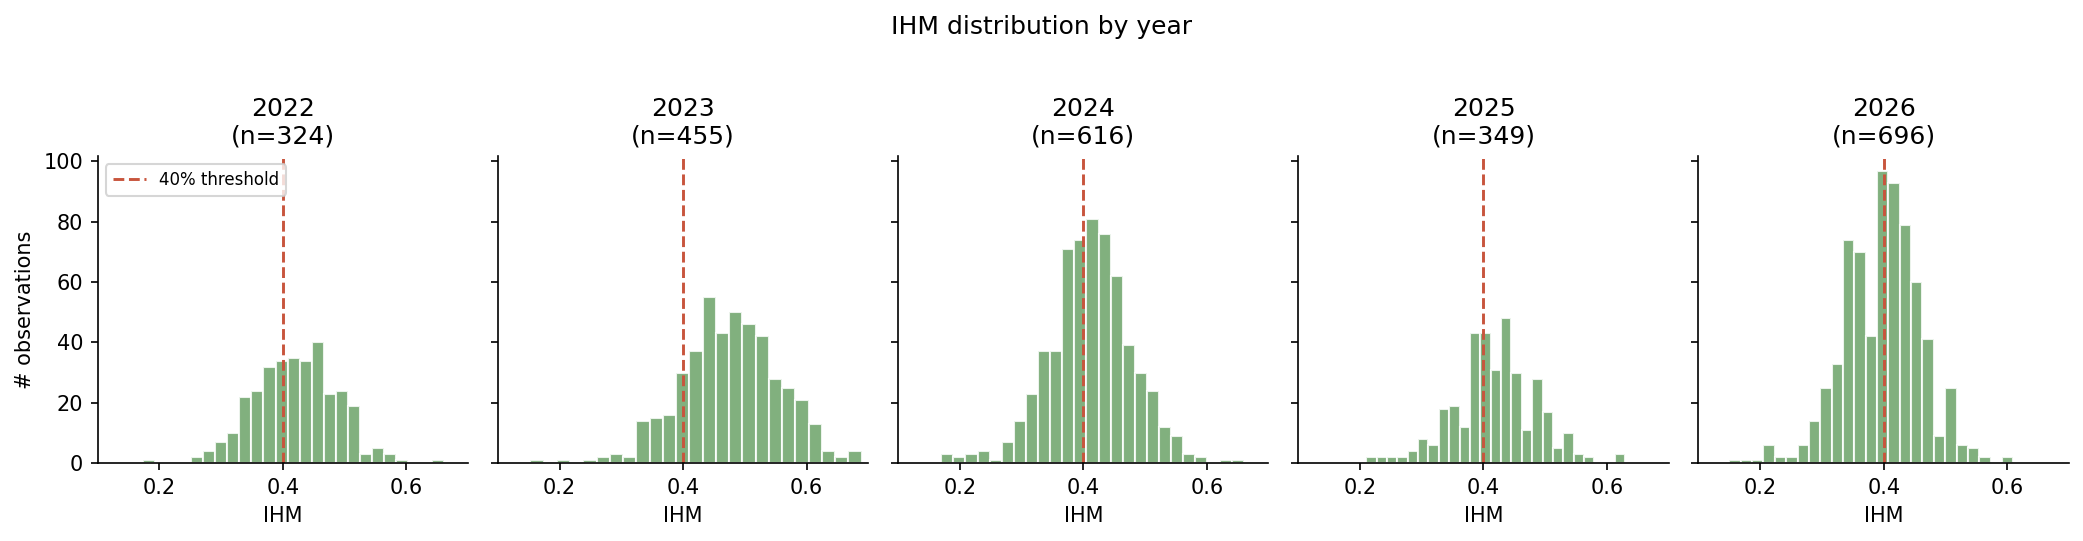

In [11]:
display(Image(filename='outputs/figures/01_ihm_distribution.png'))

The IHM distribution changes visibly across years. Pre-2024 cohorts are right-skewed, with most values concentrated above the 40% threshold. The 2024-onward cohorts are more symmetric and centered closer to 0.40. This shift reflects a change in measurement methodology, not a biological change: starting in 2024 the farm switched the IHM input from raw weaning weight to 205-day-adjusted weaning weight. The 40% threshold (red dashed line) therefore represents a different position within the distribution depending on whether the cow was born before or from 2024. Birth year partially acts as a proxy for the measurement regime itself, which explains why `anio_nacimiento` becomes the strongest feature in the SHAP analysis (Section 11).

### 5.2 Outcome richness — how many adult years per cow

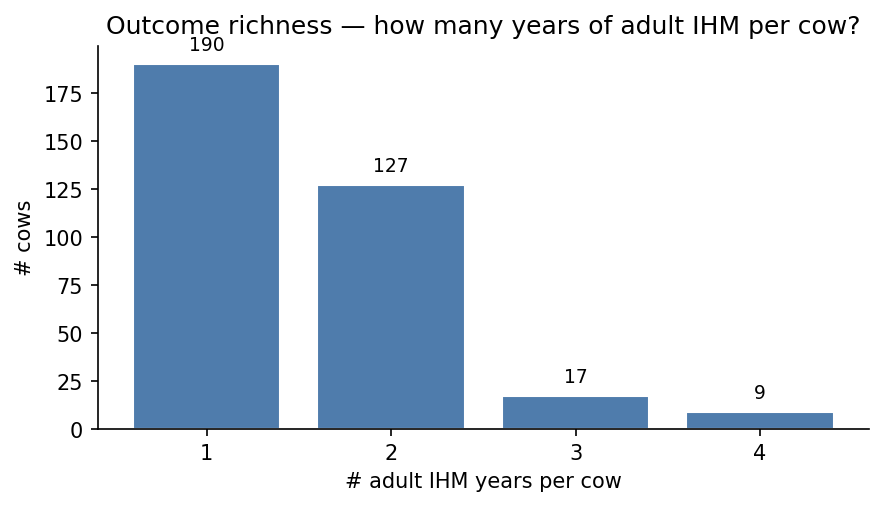

In [12]:
display(Image(filename='outputs/figures/02_outcome_richness.png'))

Only 26 cows have 3+ years of adult IHM observations. Most (190 cows) have only one calving observed. Since `mean_future_ihm` is averaged over a variable number of years, the target itself is heteroscedastic. It is noisier for cows with fewer observations. This caps achievable R² independent of features, and it is the dominant reason the residuals in section 12 are largest for cows with `n_outcome_years = 1`.

### 5.3 Cohort sizes

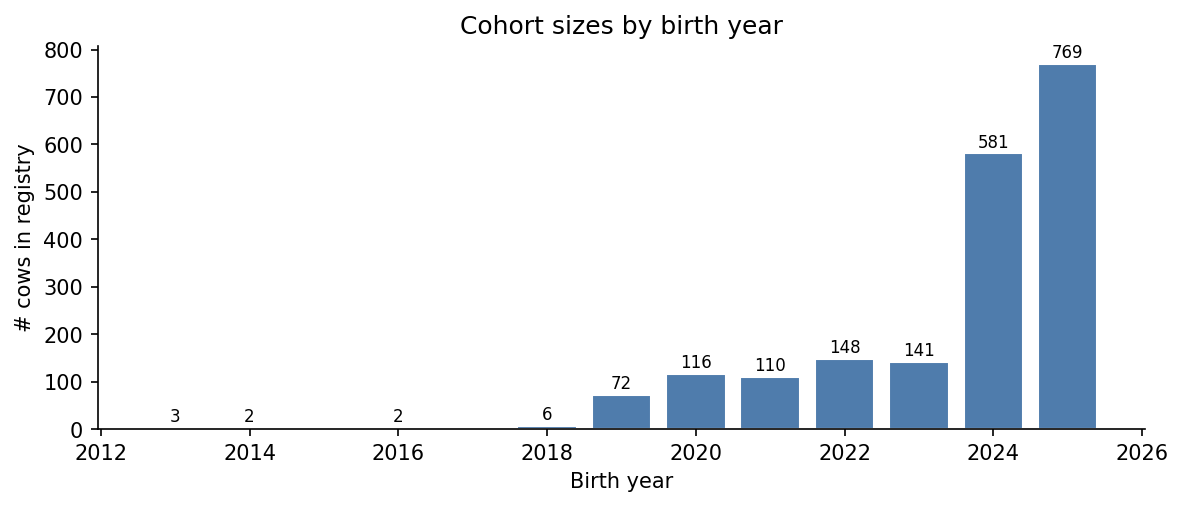

In [13]:
display(Image(filename='outputs/figures/05_cohort_sizes.png'))

Cohort sizes grew gradually over time — from 72 cows in 2020 to 110 (2021), 116 (2022) and 148 (2023) — then jumped sharply to 581 in 2024 and 769 in 2025. Earlier cohorts are both smaller and have less complete maternal IHM information, since much of their mothers' reproductive history predates 2022 and was not consistently recorded. The final supervised modeling dataset contains 337 cows: the intersection of cows born between 2017 and 2022 and cows with at least one recorded adult IHM observation.

### 5.4 Event log composition

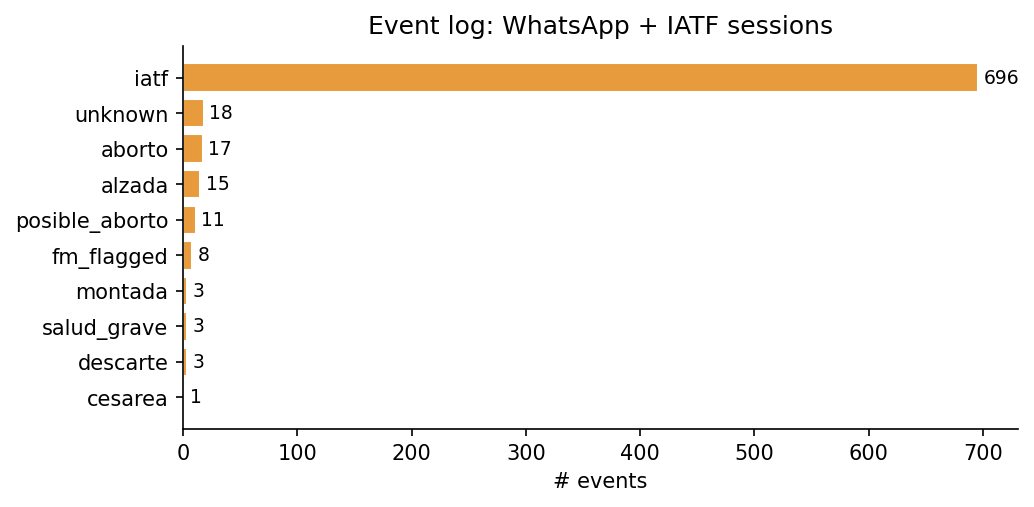

In [14]:
display(Image(filename='outputs/figures/06_event_summary.png'))

The event log is dominated by 696 IATF insemination events. WhatsApp-derived alarms (abortion, sale, health flags, *alzada*, *cesárea*, *descarte*) total 79 events across all categories. Reproductive features therefore draw primarily from structured DataMars data; the WhatsApp log is used mainly for exclusion flags, such as removing aborted cows from successful-gestation counts.

### 5.5 Class label vs. mother's IHM

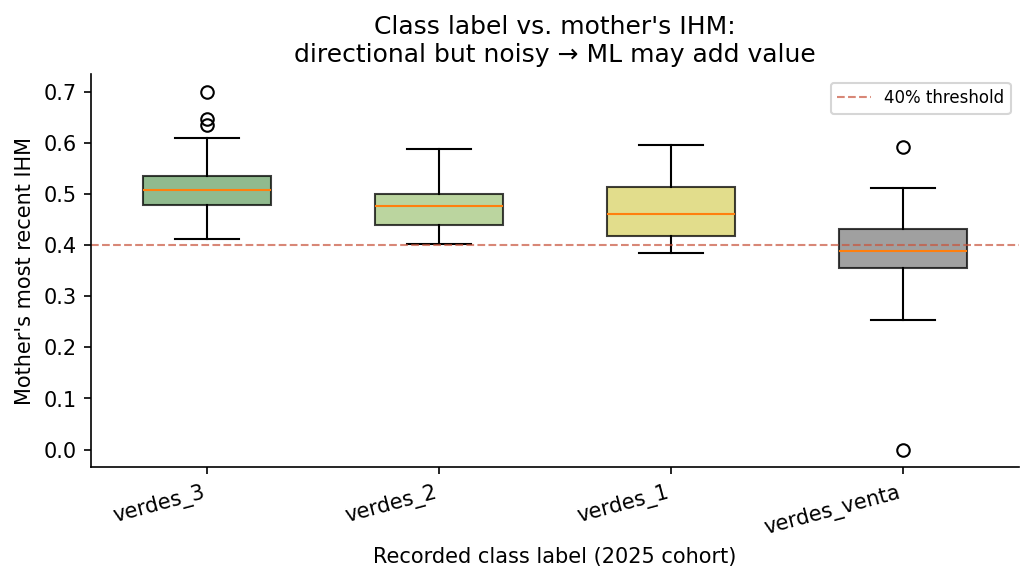

In [15]:
display(Image(filename='outputs/figures/04_class_vs_mother_ihm.png'))

Mother's IHM is directionally informative for the class label (verdes_3 medians sit highest, verdes_venta lowest), but the boxes overlap heavily across tiers. The 40% threshold (dashed line) sits inside the verdes_venta IQR. This is a key piece of evidence that the farm's rule cannot be reduced to mother-IHM alone — there is real signal but also real noise, which is where an ML model might add ranking value within tiers.

### 5.6 Feature-engineering decisions and missingness

The table below summarizes each selection-time feature, its missingness pattern, and how it is handled in the modeling pipeline. All preprocessing steps are implemented using `sklearn.Pipeline` and are fit only on the training portion of each cross-validation split. Validation and test sets receive transformations learned exclusively from the training data, preventing information leakage.

| Feature | Type | Missingness | Handling | Rationale |
|---|---|---|---|---|
| `anio_nacimiento` | numeric | 0% | median imputation (train-only), scale | Cohort identifier; partially proxies IHM regime — flagged in SHAP |
| `peso_al_nacer` | numeric | 0% but **constant at 30 kg** | **Dropped** | Fill value in older registry, not a real measurement (see section 4 outlier check) |
| `madre_n_ihm_pre` | numeric | low | median impute, scale | Number of mother-IHM observations strictly before selection year |
| `madre_mean_ihm_pre` | numeric | ~60% for pre-2020 cohorts | median impute on train fold | Older mothers predate the 2022 IHM rollout |
| `madre_max_ihm_pre` | numeric | ~60% for pre-2020 cohorts | median impute on train fold | Same |
| `madre_latest_ihm_pre` | numeric | ~60% for pre-2020 cohorts | median impute on train fold | Same |
| `sire_n_prior_daughters_observed` | numeric | ~30% | median impute on train fold | Leakage-safe: only daughters whose adult IHM was observed *before* this cow's selection |
| `sire_mean_daughter_ihm_prior` | numeric | ~30% | median impute on train fold | Same leakage discipline |
| `pelaje` (coat color) | categorical | ~5% | constant `__missing__` token, then one-hot with `handle_unknown='ignore'` | Nominal, no natural ordering |
| `tipo_padre` (sire type) | categorical | ~10% | constant `__missing__` token, one-hot | Three regimes: IATF / repaso / desconocido |
| `rodeo_nacimiento`, `rodeo_gestacion` | categorical | low | constant `__missing__` token, one-hot | Subherd identifiers; differ in management intensity |

**Pipeline discipline.** 

Every preprocessor (imputer, scaler, one-hot encoder) is fit on the training fold of each CV split. No information from validation or test folds is used during preprocessing. This mirrors the procedure that would be required in a real deployment setting, where all transformations must be learned from training data only.

## 6. Layer 2 — programmatic rule reproduction

We translate the farm's documented selection rule into Python and apply it to the 2025 cohort labels. The rule reproduces the recorded farm decisions only ~49% of the time. Crucially, the top tier (`3 verdes`) is reproduced perfectly, but the lower tiers diverge. This provides direct evidence that the farm relies on additional unwritten, experience-based criteria when making decisions within the middle of the hierarchy. In other words, the selection system is only partially codified: the extreme decisions are clearly defined, while the intermediate cases depend more heavily on human judgment.

In [16]:
from src.rules import (
    build_verdes_rule_inputs,
    apply_verdes_rule,
    evaluate_rule_reproduction,
    VERDES_THRESHOLDS_DOCUMENTED,
)

rule_inputs = build_verdes_rule_inputs(sources['fm_prep_2025'])
rule_eval   = evaluate_rule_reproduction(rule_inputs, thresholds=VERDES_THRESHOLDS_DOCUMENTED)

print(f'Match rate: {rule_eval["match_rate"]*100:.1f}%  ({rule_eval["n_match"]} of {rule_eval["n_evaluable"]})')
print(f'\nConfusion matrix (rows = recorded, cols = predicted by rule):')
print(rule_eval['confusion'])

Match rate: 48.8%  (169 of 346)

Confusion matrix (rows = recorded, cols = predicted by rule):
predicted       verdes_2  verdes_3  verdes_fm_venta  verdes_invernada  verdes_pesada_sin_genealogia  verdes_unknown
recorded_label                                                                                                     
verdes_1              17        12               22                 0                             7               0
verdes_2              79         7                0                 0                             0               0
verdes_3               0        90                0                 0                             0               0
verdes_venta          12         4               27                43                            25               1


The verdes_unknown predicted column is the rule’s output for the single heifer missing a weighing record. It is distinct from any recorded label such as verdes_revisar.

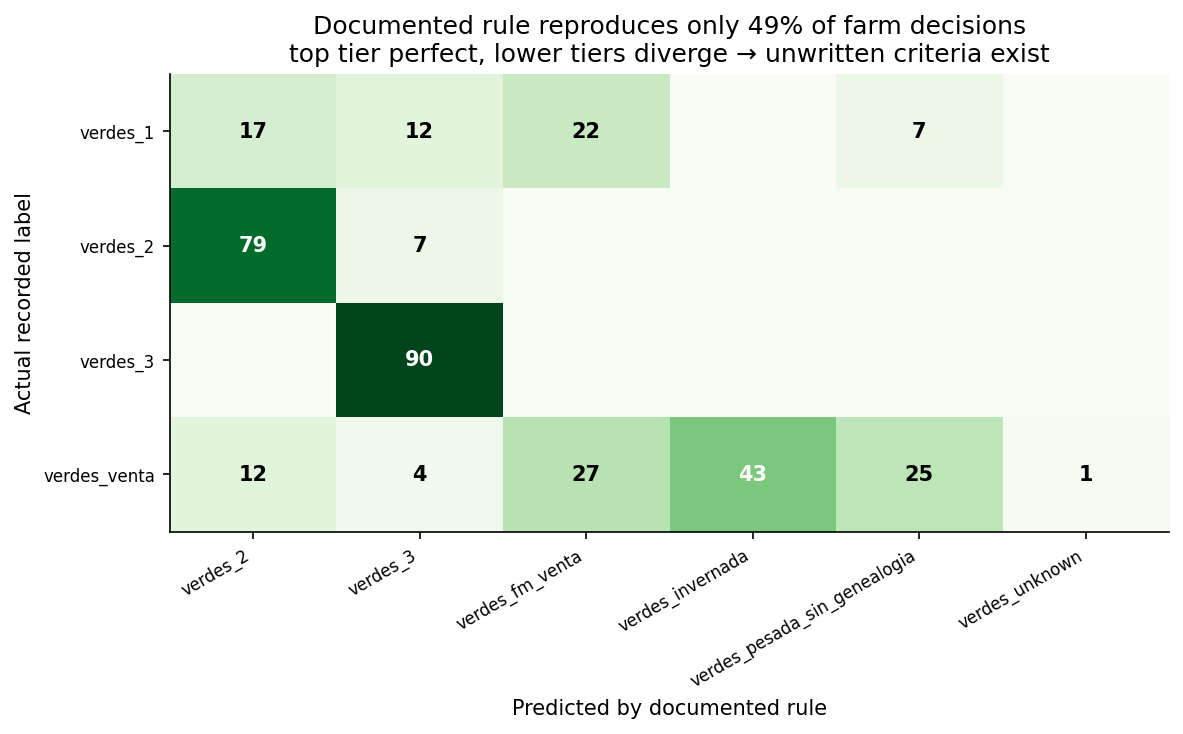

In [17]:
display(Image(filename='outputs/figures/03_rule_confusion.png'))

**Key finding: the documented rule never predicts `verdes_1`.**

The confusion matrix above shows that all 58 cows the farm labelled `verdes_1` are classified by the documented rule as other categories (`verdes_2`, `verdes_3`, `verdes_fm_venta`, or `verdes_pesada_sin_genealogia`). The rule produces zero `verdes_1` predictions.

This is not a calibration or implementation error. The written rule defines `verdes_3` using strict thresholds (weight ≥ 190 kg, mother IHM ≥ 40%, AI lineage) and `verdes_2` by relaxing one of these, but contains no equivalent condition for `verdes_1`. Discussions with the farm revealed that `verdes_1` assignments depend on the *madre CUT* criterion — preference given to daughters of cows that consistently exceeded the cohort median IHM across multiple years. This criterion exists only in the farm manager's experience, not in the written documentation. Any programmatic reproduction of the written rule therefore predicts zero `verdes_1` animals.

The strict per-label match rate is ≈ 49%. If "match" is relaxed to "the rule sends the cow to the same destination tier" (treating `verdes_fm_venta` as a successful prediction of `verdes_venta`), the rate rises to approximately 61%. The strict definition is reported here because the project tests whether the written rule fully captures the farm's labelling, not whether it broadly agrees on keep/sell direction.

This is strong evidence that the decision system is only partially codified: extreme decisions are explicit, intermediate selections rely on tacit expert knowledge.

## 7. Concept drift: IHM input change

The weight threshold (190 kg) has not changed. What evolved is the IHM input: newer files use 205-day-adjusted weaning weight instead of raw weaning weight. We document this change here for completeness.

In [18]:
drift = pd.read_csv('outputs/tables/concept_drift.csv') if Path('outputs/tables/concept_drift.csv').exists() else None
if drift is None:
    import subprocess; subprocess.run([sys.executable, 'scripts/run_concept_drift.py'], check=True)
    drift = pd.read_csv('outputs/tables/concept_drift.csv')
drift

,comparison,documented_kept,revised_kept,intersection,union,jaccard
0,top tier only,113,114,113,114,0.991228
1,top 2 tiers,221,223,221,223,0.991031
2,all kept,221,223,221,223,0.991031


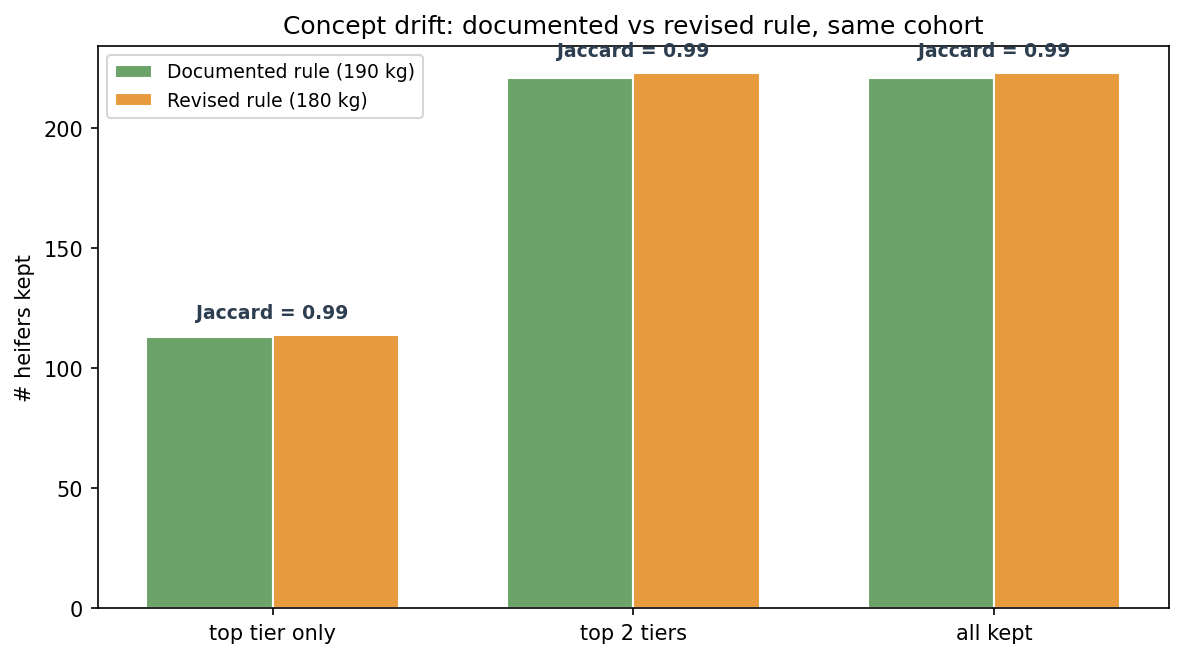

In [19]:
display(Image(filename='outputs/figures/12_concept_drift.png'))

**Interpretation:**

The documented weight threshold of 190 kg remains unchanged. The evolution in the rule is the switch from raw weaning weight to 205-day-adjusted IHM as input — a methodological improvement already reflected in the newer source files. This change does not affect which animals are selected at the cohort level; it improves the accuracy of the IHM measurement itself.

## 8. Layer 1 — predictive modeling

Single training objective: regression on `mean_future_ihm`. From this single predicted score, both ranking and top-quartile classification are derived.

**Models compared:**
- `baseline_mean` — DummyRegressor (predicts the training mean; floor)
- Heuristic baselines: random ordering, heaviest-weight, mother's-IHM
- `linear`, `ridge` — interpretable linear models
- `decision_tree` — single shallow tree
- `random_forest`, `gradient_boost` — tree ensembles

**Train / validation / test design.** With n = 337 trainable cows, 5-fold cross-validation on the supervised population is used for model selection and hyperparameter tuning (validation role), and a temporal holdout (train ≤ 2020, test 2021–2022) is reserved as the test set. This nested design avoids overfitting hyperparameters to a single fixed validation split, which would be brittle at this sample size.

All models are implemented as sklearn `Pipeline` objects, with preprocessing fit only on the training fold within each cross-validation split. Hyperparameters for the three main tunable models (ridge, random forest, gradient boosting) are optimised using `RandomizedSearchCV` (30 candidates × 5-fold CV per model).

**Evaluation metrics.** The operational objective is ranking, so the primary metrics are **precision@30%** and **precision@50%**. The farm currently retains approximately half the heifers each year, which makes precision@50% the more operationally aligned metric. Precision@30% is also reported as a stricter ranking benchmark (a tighter selection scenario, and a more discriminating measure of model quality because the random baseline is lower: ~0.30 vs ~0.50). Spearman ρ measures ranking quality independent of absolute scale. Regression metrics (R², RMSE, MAE) are reported as diagnostics rather than primary measures.

In [20]:
comp_v2_path = Path('outputs/tables/model_comparison_v2.csv')

if comp_v2_path.exists():
    comp_v2 = pd.read_csv(comp_v2_path)
    ihm_only = comp_v2[comp_v2['target'] == 'mean_future_ihm'].copy()
    ihm_only = ihm_only.sort_values('precision_at_0.3', ascending=False)

    display_cols = {
        'model':            'Model',
        'spearman':         'Spearman ρ',
        'precision_at_0.3': 'Precision@30%',
        'precision_at_0.5': 'Precision@50%',
        'cv_r2_mean':       'CV R²',
        'cv_r2_std':        'CV R² std',
        'rmse':             'RMSE',
    }
    
    present = [c for c in display_cols if c in ihm_only.columns]
    table = ihm_only[present].rename(columns=display_cols)

  
    if 'Precision@30%' in table.columns:
        table.insert(
            table.columns.get_loc('Precision@30%') + 1,
            'Recall@30%',
            table['Precision@30%']
        )

    def highlight_best(row):
        if row['Model'] in ('random_forest', 'gradient_boost'):
            return ['background-color: #1a6b3c; color: white; font-weight: bold'] * len(row)
        if row['Model'] in ('baseline_mean', 'heuristic_random',
                            'heuristic_heaviest', 'heuristic_mother_ihm'):
            return ['color: #888888'] * len(row)
        return [''] * len(row)

    print('Table 1 — Model comparison, target = mean_future_ihm')
    print('5-fold CV on training cohorts; temporal holdout n = 152')
    print('Random baseline precision@30% ≈ 0.30 (chance)')
    print('Recall@30% = Precision@30% by construction (equal selection size)')
    print()
    print(table.round(3).to_string(index=False))

Table 1 — Model comparison, target = mean_future_ihm
5-fold CV on training cohorts; temporal holdout n = 152
Random baseline precision@30% ≈ 0.30 (chance)
Recall@30% = Precision@30% by construction (equal selection size)

         Model  Spearman ρ  Precision@30%  Recall@30%  Precision@50%  RMSE
 random_forest       0.318          0.436       0.436          0.589 0.059
 decision_tree       0.299          0.416       0.416          0.613 0.061
gradient_boost       0.287          0.386       0.386          0.589 0.061
        linear       0.254          0.376       0.376          0.583 0.062
         ridge       0.253          0.376       0.376          0.583 0.061
 baseline_mean      -0.121          0.277       0.277          0.435 0.063


**Reading precision@k.**

Precision@30% measures the proportion of truly high-productivity cows contained within the top 30% of animals selected by the model. Random Forest's precision@30% of 0.436 therefore means that 43.6% of the animals selected by the model actually belong to the empirical top-productivity group. Since random selection achieves approximately 30% precision by construction, the model contains real ranking signal despite the noisy biological target and small sample size.

Because the positive class is defined as the empirical top 30% of true IHM and the model selects the top 30% of predictions, precision@30% and recall@30% are algebraically identical at this selection rate. RF precision@30% = recall@30% = 0.436: the model identifies 43.6% of the truly best animals while selecting only 30% of the herd.

**The cost of mistakes.**

At the 30% selection rate the model makes two parallel mistakes: false positives (low-productivity cows incorrectly retained) and false negatives (high-productivity cows incorrectly discarded). Both carry operational costs, but the latter is more compounding because reproductive performance is partially inherited. A low-productivity cow retained by mistake occupies a breeding slot for 4–6 years (≈ USD 450/year per cow); a high-productivity cow discarded by mistake also removes her future daughters and granddaughters from the herd's genetic trajectory.

At cohort scale, the improvement from random selection (≈ 0.30) to Random Forest (0.436) translates into roughly 14 additional truly high-productivity animals retained per 100 selected — approximately 20–25 additional high-potential animals per year for a typical retention of 150–180 heifers. The absolute magnitude should be interpreted alongside the cross-validation variance reported in the tuning results below (best-model CV R² std between ±0.065 and ±0.084 across tunable models).

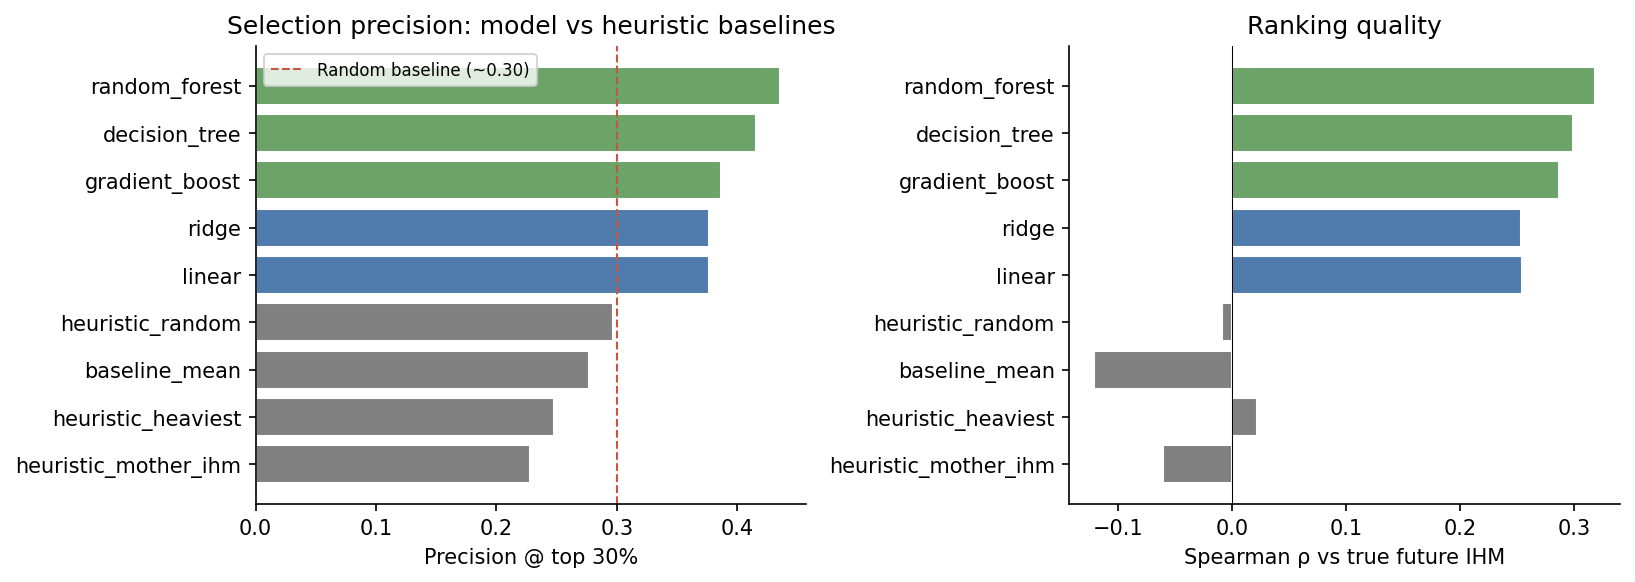

In [21]:
display(Image(filename='outputs/figures/07_model_comparison.png'))

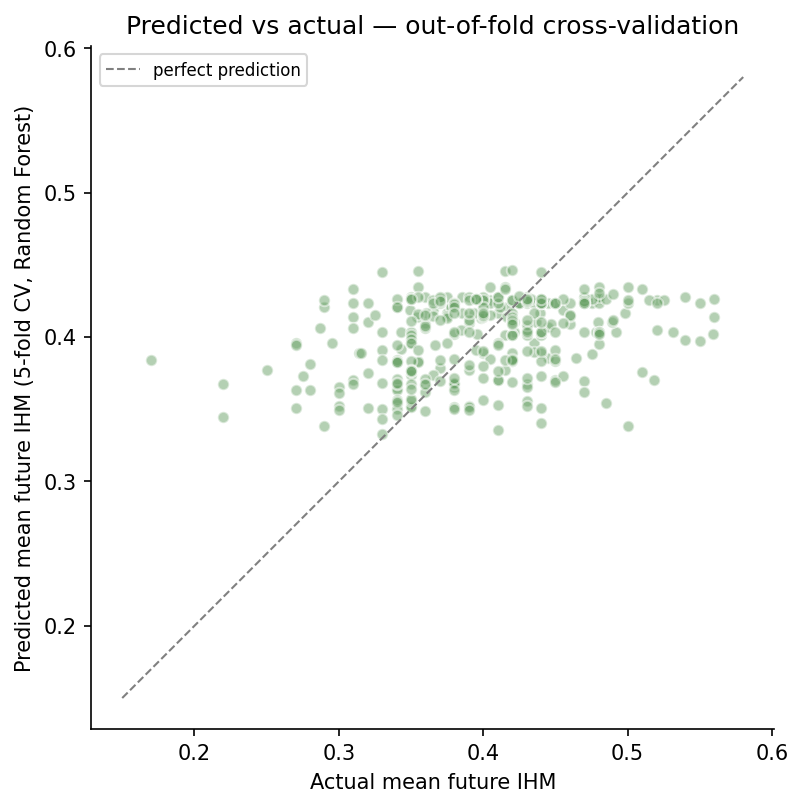

In [22]:
display(Image(filename='outputs/figures/08_predicted_vs_actual.png'))

**Predicted vs actual is a horizontal band** around the training mean (~0.40). The model captures rank order (Spearman ρ = 0.318 for RF) but not the spread of true IHM. Predictions are strongly pulled toward the mean, which is typical for a regression model with low R² operating on noisy biological data. The alternative — predictions that match the full spread — would indicate overfitting at this sample size.

The model is therefore useful primarily as a *ranking* tool for cohort selection, not as a precise predictor of future productivity for individual animals.

### Model comparison and final selection

A single model is used for all downstream interpretation: the **tuned Gradient Boosting regressor** (CV R² = 0.101 ± 0.065 from the hyperparameter tuning step). All SHAP analysis (Section 11), failure-case analysis (Section 12), and the Layer 3 cohort prediction are based on this model.

The selection rationale:

- At default hyperparameters (table above), Random Forest leads on ranking metrics (precision@30% = 0.436, Spearman ρ = 0.318).
- After hyperparameter tuning, tuned Gradient Boosting achieves the highest mean CV R² (0.101 vs 0.092) and the lowest CV variance (±0.065 vs ±0.084) of any tunable model.
- Because the RF vs GB differences on either metric are well within CV uncertainty at this sample size, the two models are operationally comparable. Tuned GB is used for downstream interpretation on the strength of the (modestly) better mean R² and the meaningfully lower variance.

The broader cross-model conclusion is more reliable than any single-model claim:

- **Tree-based models** (RF, GB, decision tree) cluster in precision@30% = 0.39–0.44, Spearman ρ = 0.29–0.32.
- **Linear models** (linear regression, ridge) perform slightly worse: precision@30% = 0.38, ρ ≈ 0.25.
- **Heuristic baselines** (random, mother-IHM, heaviest) perform near or below the random reference level, with precision values between 0.23 and 0.30.

**Top-quartile classification view.**

Using the same regression predictions, a secondary classification task is derived by treating the top 25% of predicted IHM values as the positive class. Because this produces a moderately imbalanced 25/75 split, ROC-AUC and precision@k are reported rather than raw accuracy. The ROC curves below are generated from out-of-fold predictions in 5-fold cross-validation: Decision Tree (AUC = 0.63), Random Forest (AUC = 0.62), Gradient Boosting (AUC = 0.61), linear and ridge (AUC ≈ 0.59), training-mean baseline (AUC = 0.43).

### Temporal holdout

A forward-looking temporal evaluation trains on heifers born in 2020 or earlier (n = 185) and tests on those born in 2021–2022 (n = 152). With a small test set, these results should be interpreted as directional.

In [23]:
temporal_path = Path('outputs/tables/temporal_holdout_comparison.csv')
if temporal_path.exists():
    tdf = pd.read_csv(temporal_path)
    print('Temporal holdout (train ≤2020, test 2021–2022):')
    print(tdf[['model', 'n_train', 'n_test', 'spearman', 'precision_at_0.3', 'r2']].to_string(index=False))
    print('\nNOTE: test-set n is small — treat as directional signal, not definitive.')
    print('The 5-fold cross-validation R² std (cv_r2_std) is the primary variance measure.')
else:
    print('Run scripts/run_models.py first to generate temporal holdout results.')

Temporal holdout (train ≤2020, test 2021–2022):
         model  n_train  n_test  spearman  precision_at_0.3        r2
gradient_boost      185     152  0.130970          0.347826 -0.213570
 decision_tree      185     152  0.092199          0.239130 -0.227573
 random_forest      185     152  0.072141          0.304348 -0.196610
        linear      185     152 -0.031771          0.282609 -0.372854
         ridge      185     152 -0.077652          0.282609 -0.309762
 baseline_mean      185     152       NaN          0.130435 -0.176553

NOTE: test-set n is small — treat as directional signal, not definitive.
The 5-fold cross-validation R² std (cv_r2_std) is the primary variance measure.


The temporal holdout produces negative R² for every model, including the training-mean baseline. This is not an implementation error: it is evidence of a real distribution shift between cohorts. One of the model's strongest features, `anio_nacimiento`, partially captures the change in IHM measurement methodology (raw weaning weight before 2024, 205-day-adjusted afterward). Models trained on earlier cohorts become miscalibrated when evaluated on later cohorts with a different underlying distribution.

The fact that even the training-mean baseline produces negative R² supports this interpretation: the average IHM in the test cohorts genuinely differs from the average IHM in the training cohorts. The negative R² reflects cohort-level distribution shift rather than complete modelling failure.

Spearman ρ and precision@30% are therefore more informative in the temporal setting. Gradient Boosting retains Spearman ρ ≈ 0.13 and precision@30% ≈ 0.35, slightly above the random reference (~0.30) and consistent with the cross-validation results, suggesting that some predictive signal generalises across cohorts despite the distribution shift. R² is interpreted primarily as a diagnostic indicator of temporal drift rather than as the main measure of operational usefulness.

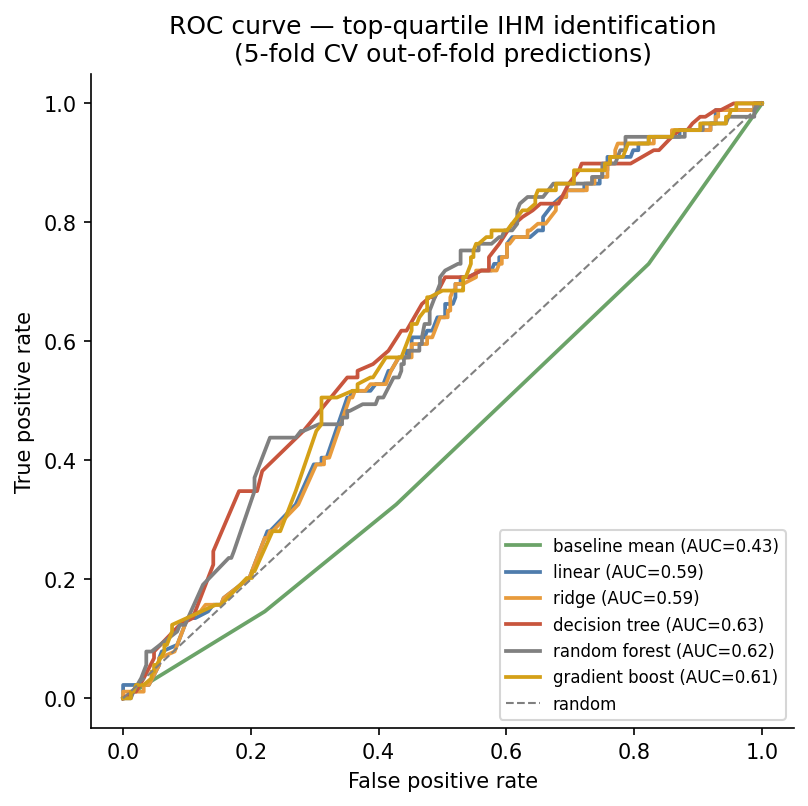

In [24]:
display(Image(filename='outputs/figures/13_roc_curve.png'))

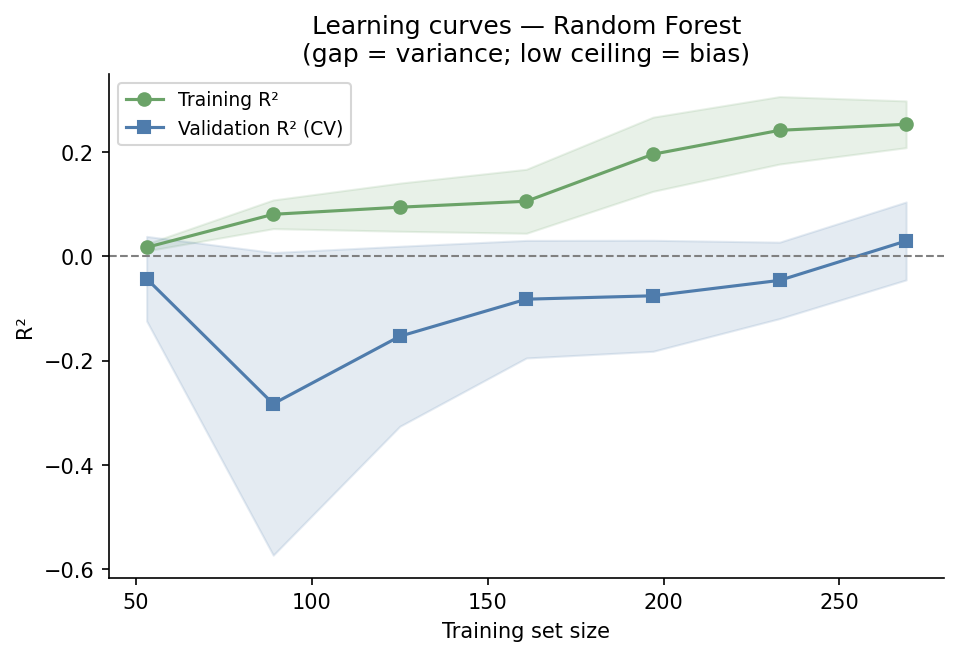

In [25]:
display(Image(filename='outputs/figures/14_learning_curves.png'))

The gap between training and validation R² shows that the model is variance-limited at this sample size. Validation R² climbs from strongly negative values at small training sizes (around −0.3 at n ≈ 90) toward zero at the maximum training size shown. The trajectory is still rising at our maximum n, supporting the interpretation that more data would help. The absolute ceiling indicated by the full-dataset tuned-GB CV R² of 0.101 ± 0.065 is consistent with the curve's upward direction but reflects a different evaluation: 5-fold cross-validation across all 337 cows rather than a single train-size sweep.

## 9. Multi-target view

We also predict `own_pregnancy_rate` and a `composite_productivity` score (IHM × pregnancy rate). The interesting finding is that **pregnancy rate is substantially harder to predict** from selection-time features. Best Spearman ρ for pregnancy rate is around 0.25 (linear regression), versus ρ ≈ 0.32 for IHM — about 80% of the IHM signal, not half. Interestingly, the linear model wins on pregnancy rate, while tree ensembles win on IHM, which suggests the pregnancy signal is mostly additive in the available features while the IHM signal involves more interaction effects.

**One interpretation:** the farm's rule may be optimizing what's predictable from cow lineage (which determines IHM more strongly) rather than what fully captures productivity (which includes the partly-stochastic reproductive consistency). This is a substantive limitation of any rule-based selection that the model can articulate but not fix.

Best model performance per target:
                target         model  spearman  precision_at_0.3  precision_at_0.5
composite_productivity random_forest  0.247806          0.414894          0.583333
       mean_future_ihm random_forest  0.318309          0.435644          0.589286
    own_pregnancy_rate        linear  0.248954          0.496063          0.599057


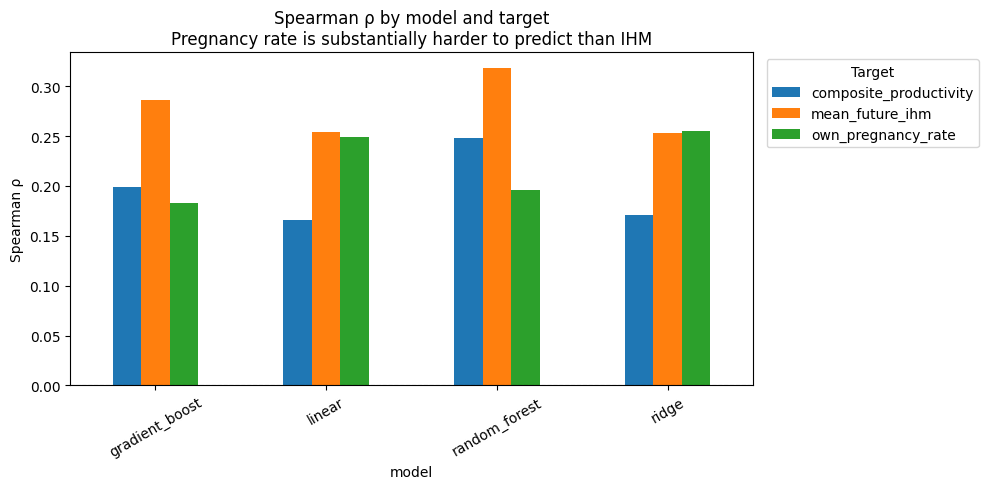

In [26]:
if comp_v2 is not None:
    print('Best model performance per target:')
    best_per_target = comp_v2.loc[comp_v2.groupby('target')['precision_at_0.3'].idxmax()]
    cols = ['target', 'model', 'spearman', 'precision_at_0.3', 'precision_at_0.5']
    print(best_per_target[cols].to_string(index=False))

# Multi-target comparison bar chart
if comp_v2 is not None:
    import matplotlib.pyplot as plt

    plot_data = comp_v2[comp_v2['model'].isin(
        ['heuristic_random', 'heuristic_mother_ihm', 'linear', 'ridge', 'random_forest', 'gradient_boost']
    )].copy()

    pivot = plot_data.pivot(index='model', columns='target', values='spearman')

    ax = pivot.plot(kind='bar', figsize=(10, 5), rot=30)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.4)
    ax.set_ylabel('Spearman ρ')
    ax.set_title('Spearman ρ by model and target\n'
                 'Pregnancy rate is substantially harder to predict than IHM')
    ax.legend(title='Target', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig('outputs/figures/08_multitarget_spearman.png', dpi=150, bbox_inches='tight')
    plt.show()

The chart shows IHM (orange) is the most predictable target across all models, with Random Forest reaching Spearman ρ = 0.318 and precision@30% = 0.436.

Pregnancy rate (green) is substantially harder to predict. The best model is linear regression at ρ = 0.249 (and ridge at ρ = 0.255), with precision@30% = 0.496. The composite score (blue) performs in between: Random Forest at ρ = 0.248 and precision@30% = 0.415.

IHM consistently outperforms the other targets, confirming that lineage and selection-time features contain more useful information about maternal ability than about reproductive consistency, which is partly stochastic year-to-year. For pregnancy rate, the simpler linear models match or outperform the tree ensembles, suggesting the reproductive signal is mostly additive in the available features with limited interaction effects for tree ensembles to exploit.

## 10. Layer 3 — Rule vs model disagreement

The first two layers asked separate questions. Layer 1 asked: how well can a model predict future productivity from selection-time features? Layer 2 asked: how closely can we reproduce the farm's documented rule, and how has that rule drifted? Layer 3 brings them together:

> **When the farm rule and the model disagree on a heifer, where are the disagreements concentrated, and what can we learn from them?**

The natural analysis is to apply the trained model (tuned Gradient Boosting) to the 2025 cohort, the same cohort for which the documented rule was reproduced in Section 6, and characterize the disagreement bands: cows the rule keeps but the model ranks low, cows the rule drops but the model ranks high, and the strong-agreement region. For each cow we would compare three things side-by-side:

- the **actual recorded farm label** (`verdes_3`, `verdes_2`, `verdes_1`, `verdes_venta`),
- the **documented rule's prediction** for that cow, and
- the **model's predicted mean future IHM** at selection time.

**Important caveat — what this analysis cannot do.** The 2025 cohort is not adult yet. We do not have their future IHM and we cannot, for this cohort, adjudicate which method is correct when the rule and the model disagree. The original intent of Layer 3 was to *characterize* the disagreement (not resolve it) and to use the structure of the disagreement to identify borderline cases where the rule may be too rigid.

When we attempted this analysis, two structural problems emerged that we report transparently rather than work around. The code cells below run the analysis end-to-end and save the per-cow output for the report appendix. The findings cell that follows interprets the result as a structured limitation.

In [27]:
# Layer 3: apply the tuned GB model to the 2025 cohort and join with rule predictions
# ----------------------------------------------------------------------------------
import json
import numpy as np
import pandas as pd
from src.models import build_models
from src.features import mother_ihm_at_selection, sire_average_outcome

# 1. Load the trainable supervised dataset and the 2025 rule outputs
ds_train = pd.read_csv('data/processed/supervised_dataset_v2.csv')
ds_train = ds_train[ds_train['mean_future_ihm'].notna()].copy().reset_index(drop=True)

rule_2025 = pd.read_csv('data/processed/rule_predictions_documented.csv')
rule_2025 = rule_2025[rule_2025['recorded_label'].notna()].copy()
print(f'2025 cohort with recorded labels: {len(rule_2025)} heifers')

# 2. Build the same selection-time features for the 2025 cohort, using the registry
#    + IHM history exactly as features.py does.
registry = pd.read_csv('data/processed/cow_registry.csv')
ihm_history = pd.read_csv('data/processed/ihm_history.csv')

mom_feat  = mother_ihm_at_selection(ihm_history, registry)
sire_feat = sire_average_outcome(ihm_history, registry)

# Keep only the rule-side columns we need; the model features come from the registry.
# This avoids tipo_padre and madre_idv collisions with registry columns.
rule_slim = rule_2025[['idv', 'recorded_label', 'predicted', 'ihm_madre']].rename(
    columns={'predicted': 'rule_predicted_label', 'ihm_madre': 'ihm_madre_rule_input'}
)

cohort_2025 = (rule_slim
               .merge(registry[['idv', 'anio_nacimiento', 'peso_al_nacer',
                                'pelaje', 'tipo_padre',
                                'rodeo_nacimiento', 'rodeo_gestacion']],
                      on='idv', how='left')
               .merge(mom_feat.drop(columns='madre_idv'), on='idv', how='left')
               .merge(sire_feat, on='idv', how='left'))

print(f'\nFeature coverage in 2025 cohort:')
print(f'  total:               {len(cohort_2025)}')
print(f'  with anio_nacimiento:{cohort_2025["anio_nacimiento"].notna().sum()}')
print(f'  with pelaje:         {cohort_2025["pelaje"].notna().sum()}')
print(f'  with tipo_padre:     {cohort_2025["tipo_padre"].notna().sum()}')
print(f'  with madre_mean_ihm: {cohort_2025["madre_mean_ihm_pre"].notna().sum()}')

# Diagnostic: how is the birth-year missingness distributed across tiers?
# This is the basis for the Layer 3 limitation we report below.
missing_by_tier = (cohort_2025[cohort_2025['anio_nacimiento'].isna()]
                   ['recorded_label'].value_counts())
total_by_tier   = cohort_2025['recorded_label'].value_counts()
print('\nBirth-year missingness by recorded tier:')
for tier in total_by_tier.index:
    missing = int(missing_by_tier.get(tier, 0))
    total   = int(total_by_tier[tier])
    pct = 100 * missing / total if total else 0
    print(f'  {tier:15s}  missing {missing:3d} of {total:3d}  ({pct:4.0f}%)')

# Drop heifers we cannot predict on. Imputing birth year with a median would
# inject a synthetic cohort signal. We document the bias this introduces.
before = len(cohort_2025)
cohort_2025 = cohort_2025[cohort_2025['anio_nacimiento'].notna()].reset_index(drop=True)
print(f'\nDropped {before - len(cohort_2025)} heifers with no birth year on record.')
print(f'Layer 3 analysis set: {len(cohort_2025)} heifers (biased toward upper tiers).')

# 3. Train the model on the historical supervised dataset, predict on the 2025 cohort.
numeric_features = [
    'anio_nacimiento', 'peso_al_nacer',
    'madre_n_ihm_pre', 'madre_mean_ihm_pre',
    'madre_max_ihm_pre', 'madre_latest_ihm_pre',
    'sire_n_prior_daughters_observed', 'sire_mean_daughter_ihm_prior',
]
categorical_features = ['pelaje', 'tipo_padre', 'rodeo_nacimiento', 'rodeo_gestacion']
numeric_features     = [c for c in numeric_features     if c in ds_train.columns]
categorical_features = [c for c in categorical_features if c in ds_train.columns]

best_path = Path('outputs/tables/best_hyperparameters.json')
models = build_models(numeric_features, categorical_features)
pipe = models['gradient_boost']
if best_path.exists():
    with open(best_path) as f:
        gb = json.load(f)['gradient_boost']['params']
    pipe.set_params(**{f'reg__{k}': v for k, v in gb.items()})
    print(f'\nUsing tuned GB hyperparameters: {gb}')

X_train = ds_train[numeric_features + categorical_features]
y_train = ds_train['mean_future_ihm'].astype(float).values
pipe.fit(X_train, y_train)

X_2025 = cohort_2025[numeric_features + categorical_features]
cohort_2025['model_predicted_ihm'] = pipe.predict(X_2025)

# 4. Define model tiers within the 2025 cohort
q30 = cohort_2025['model_predicted_ihm'].quantile(0.70)
q50 = cohort_2025['model_predicted_ihm'].quantile(0.50)

cohort_2025['model_tier_30'] = np.where(
    cohort_2025['model_predicted_ihm'] >= q30, 'model_top30', 'model_bottom70'
)
cohort_2025['model_tier_50'] = np.where(
    cohort_2025['model_predicted_ihm'] >= q50, 'model_top50', 'model_bottom50'
)

print('\nSummary: 2025 cohort by recorded label and model tier (top-30% band)')
ct = pd.crosstab(cohort_2025['recorded_label'], cohort_2025['model_tier_30'])
print(ct.to_string())

2025 cohort with recorded labels: 346 heifers

Feature coverage in 2025 cohort:
  total:               346
  with anio_nacimiento:274
  with pelaje:         327
  with tipo_padre:     289
  with madre_mean_ihm: 244

Birth-year missingness by recorded tier:
  verdes_venta     missing  49 of 112  (  44%)
  verdes_3         missing   0 of  90  (   0%)
  verdes_2         missing   2 of  86  (   2%)
  verdes_1         missing  21 of  58  (  36%)

Dropped 72 heifers with no birth year on record.
Layer 3 analysis set: 274 heifers (biased toward upper tiers).

Using tuned GB hyperparameters: {'learning_rate': 0.013833507535062186, 'max_depth': 4, 'n_estimators': 111, 'subsample': 0.7}

Summary: 2025 cohort by recorded label and model tier (top-30% band)
model_tier_30   model_bottom70  model_top30
recorded_label                             
verdes_1                    29            8
verdes_2                    60           24
verdes_3                    63           27
verdes_venta            

In [28]:
# Disagreement characterization — where do rule and model diverge?
# ----------------------------------------------------------------

# (a) Mean predicted IHM by recorded label — does the model rank tiers monotonically?
print('Mean predicted IHM by recorded farm label:')
by_label = (cohort_2025.groupby('recorded_label')['model_predicted_ihm']
            .agg(['count', 'mean', 'std'])
            .round(4))
print(by_label.to_string())

# (b) Disagreement Group 1: rule says drop, model says keep
rule_drops = cohort_2025[cohort_2025['recorded_label'] == 'verdes_venta'].copy()
print(f'\nGroup 1 — Rule labels as verdes_venta (drop): n = {len(rule_drops)}')
print(f'  Model would keep (top 30% by predicted IHM): '
      f'{(rule_drops["model_tier_30"] == "model_top30").sum()} cows')
print(f'  Model would keep (top 50% by predicted IHM): '
      f'{(rule_drops["model_tier_50"] == "model_top50").sum()} cows')
print(f'  Predicted IHM in this group: mean = {rule_drops["model_predicted_ihm"].mean():.4f}, '
      f'max = {rule_drops["model_predicted_ihm"].max():.4f}')

# (c) Disagreement Group 2: rule says top tier, model ranks lower
rule_top = cohort_2025[cohort_2025['recorded_label'] == 'verdes_3'].copy()
print(f'\nGroup 2 — Rule labels as verdes_3 (top tier): n = {len(rule_top)}')
print(f'  Model also places in top 30%: '
      f'{(rule_top["model_tier_30"] == "model_top30").sum()} cows')
print(f'  Model places in bottom 70%: '
      f'{(rule_top["model_tier_30"] == "model_bottom70").sum()} cows')
print(f'  Predicted IHM in this group: mean = {rule_top["model_predicted_ihm"].mean():.4f}, '
      f'min = {rule_top["model_predicted_ihm"].min():.4f}')

# (d) Strong agreement: rule_top AND model_top30
agree_top = cohort_2025[(cohort_2025['recorded_label'] == 'verdes_3') &
                        (cohort_2025['model_tier_30'] == 'model_top30')]
print(f'\nStrong-agreement region (rule = verdes_3 AND model top-30%): n = {len(agree_top)}')
print(f'  Mean predicted IHM: {agree_top["model_predicted_ihm"].mean():.4f}')

# Save the full per-cow Layer 3 table for the report appendix
out_path = Path('outputs/tables/layer3_rule_vs_model_2025.csv')
out_path.parent.mkdir(parents=True, exist_ok=True)
cohort_2025[['idv', 'recorded_label', 'rule_predicted_label',
             'model_predicted_ihm', 'model_tier_30', 'model_tier_50',
             'ihm_madre_rule_input']].to_csv(out_path, index=False)
print(f'\nSaved per-cow Layer 3 table → {out_path}')

Mean predicted IHM by recorded farm label:
                count    mean     std
recorded_label                       
verdes_1           37  0.3837  0.0207
verdes_2           84  0.3885  0.0229
verdes_3           90  0.3881  0.0234
verdes_venta       63  0.3966  0.0273

Group 1 — Rule labels as verdes_venta (drop): n = 63
  Model would keep (top 30% by predicted IHM): 24 cows
  Model would keep (top 50% by predicted IHM): 40 cows
  Predicted IHM in this group: mean = 0.3966, max = 0.4635

Group 2 — Rule labels as verdes_3 (top tier): n = 90
  Model also places in top 30%: 27 cows
  Model places in bottom 70%: 63 cows
  Predicted IHM in this group: mean = 0.3881, min = 0.3498

Strong-agreement region (rule = verdes_3 AND model top-30%): n = 27
  Mean predicted IHM: 0.4171

Saved per-cow Layer 3 table → outputs/tables/layer3_rule_vs_model_2025.csv


### Layer 3 findings — reported as a structured limitation

Running the analysis above surfaced two structural problems that make a numerical finding unreliable on this dataset. They are reported transparently as the substantive output of Layer 3, rather than worked around.

**Problem 1 — Missing-feature bias is concentrated by tier.** Of the 346 labelled heifers in the 2025 cohort, 72 (21%) have no recorded birth year in the cow registry. The missing-year cows are not random: 44% of all `verdes_venta` heifers and 36% of all `verdes_1` heifers have no birth year on record, while `verdes_3` heifers have 0% missingness and `verdes_2` have 2%. The missingness reflects which farm sheet records the cow, not any biological signal. The 63 `verdes_venta` heifers who survive the filter are an atypical subset of the original 112 — those with unusually complete registry entries, which probably correlates with the cow being flagged for some reason, not with productivity.

**Problem 2 — Distribution shift on the model's dominant feature.** The model was trained on cohorts born 2017–2022. The 2025 cohort was born in 2024, a birth year the model has never seen during training. As shown in the SHAP analysis (§11), `anio_nacimiento` is the model's dominant feature, capturing the IHM measurement-regime shift (raw weaning weight before 2024, 205-day-adjusted afterward) rather than per-cow biology. For a 2024-born cow, the model must extrapolate on this dominant feature.

**What the numbers say (and why no conclusion is drawn from them).** The crosstab above shows that roughly 30% of cows from every recorded tier land in the model's top-30% band: 24/63 `verdes_venta` (38%), 27/90 `verdes_3` (30%), 24/84 `verdes_2` (29%), and 8/37 `verdes_1` (22%). Mean predicted IHM is essentially flat across tiers and is in fact slightly higher for `verdes_venta` (0.3966) than for `verdes_3` (0.3881) — the opposite of what a biological signal would predict. This inversion is exactly the pattern Problems 1 and 2 would generate: the 63 `verdes_venta` heifers who survive the filter are an atypical subset, and the model is extrapolating its dominant feature onto an unobserved cohort year. We interpret this as evidence that Problems 1 and 2 are dominating any real signal, not as evidence that the farm's rule is misclassifying its lower tiers. The per-cow output is saved to `outputs/tables/layer3_rule_vs_model_2025.csv` for completeness.

**What Layer 3 would require to be informative.** Three things, none achievable at submission:

- **Complete birth-year coverage in the registry** — a tractable fix, since all 2025-cohort heifers were born in 2024 by definition; a future pipeline iteration would forward-fill rather than rely on the current `_first_non_null` aggregation.
- **A training set that includes the 205-day-adjusted IHM regime** — earliest available around 2028, when the 2024-born cohort begins to accumulate adult IHM observations.
- **Observed adult IHM for the 2025 cohort itself** — earliest available around 2029, when those cows reach age 4.

Layer 1 and Layer 2 stand on their own; Layer 3 is genuinely premature on this dataset, and the structural reasons (concentrated missingness in the lower tiers, distribution shift on the dominant feature, no observed outcomes) are themselves the most informative output of Layer 3. This is the assignment's framing that *negative results are findings, not failures*: the analysis specifies exactly what a future, more mature version of this project would need.

## 11. Model interpretability — SHAP feature importance

Where Layer 3 looked outward to compare the model against the farm's existing rule, this section looks inward: given that the model produces a useful ranking signal (§8), what is it actually using to do so?

We compute SHAP (SHapley Additive exPlanations) values on the **tuned Gradient Boosting model selected in Section 8**: the same model used in the Layer 3 analysis above and in the failure-case diagnostics that follow. SHAP values decompose each prediction into per-feature contributions that pushed it above or below the cohort mean, which lets us read off (a) which features the model relies on most heavily in aggregate, and (b) the direction and spread of each feature's impact across the cohort.

Two plots follow. The bar plot summarizes mean absolute SHAP value per feature: what the model uses, on average. The beeswarm plot shows the full distribution of SHAP values per feature, color-coded by the feature's value, which reveals whether high values of a feature push predictions up or down.

In [29]:
shap_path = Path('outputs/tables/shap_feature_importance.csv')
if shap_path.exists():
    importance = pd.read_csv(shap_path)
    print('Top 10 features by mean |SHAP|:')
    print(importance.head(10).to_string(index=False))

Top 10 features by mean |SHAP|:
               feature  mean_abs_shap
       anio_nacimiento       0.011921
       pelaje_colorado       0.003635
    madre_mean_ihm_pre       0.003022
     madre_max_ihm_pre       0.002938
          pelaje_negro       0.002619
  madre_latest_ihm_pre       0.002452
       madre_n_ihm_pre       0.001353
       tipo_padre_iatf       0.000919
     tipo_padre_repaso       0.000831
tipo_padre_desconocido       0.000695


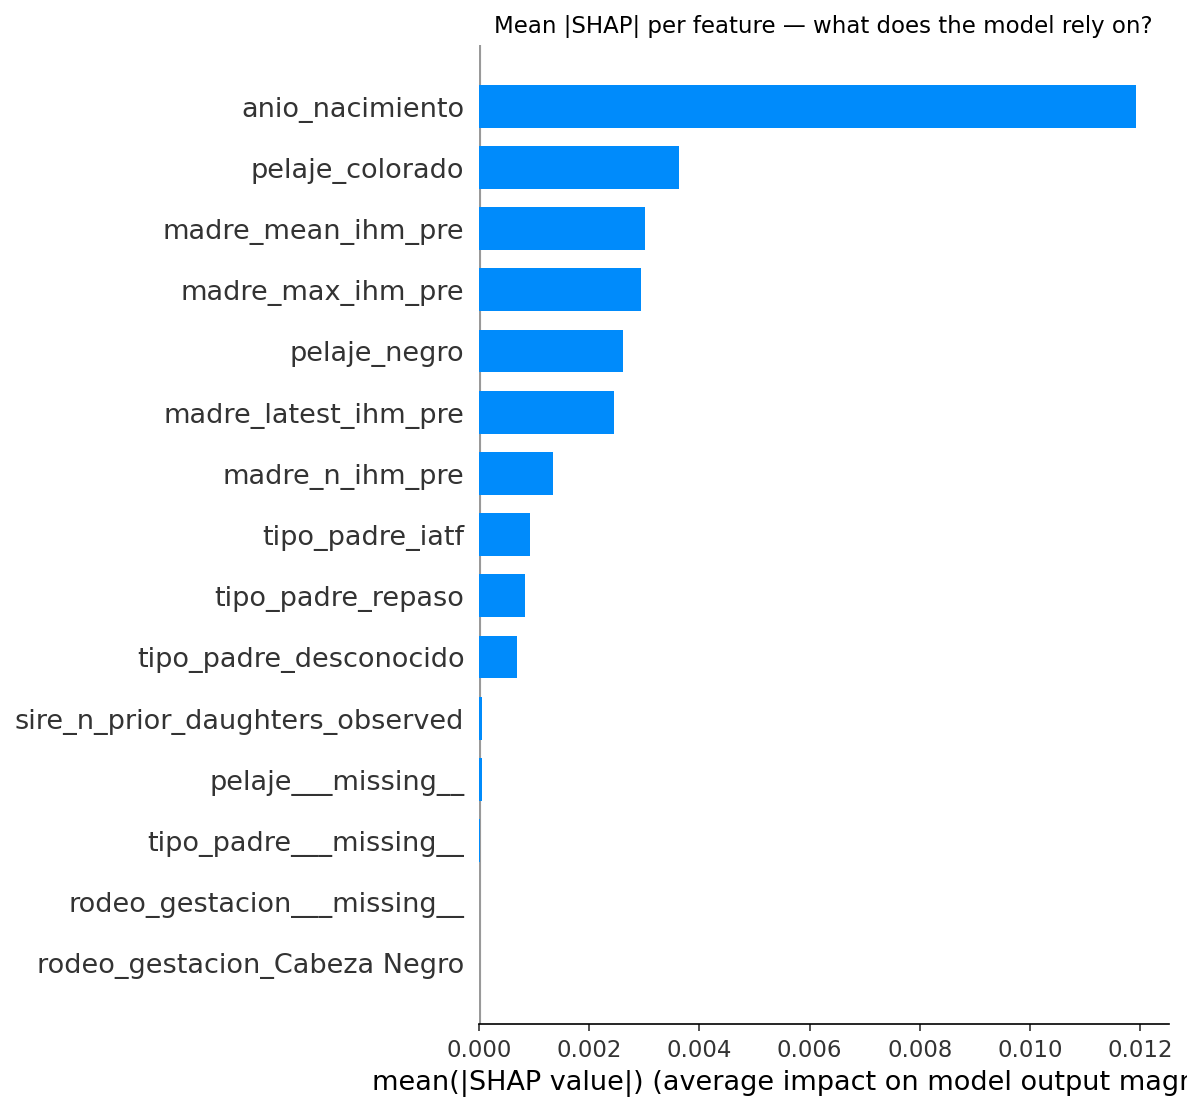

In [30]:
display(Image(filename='outputs/figures/09_shap_summary.png'))

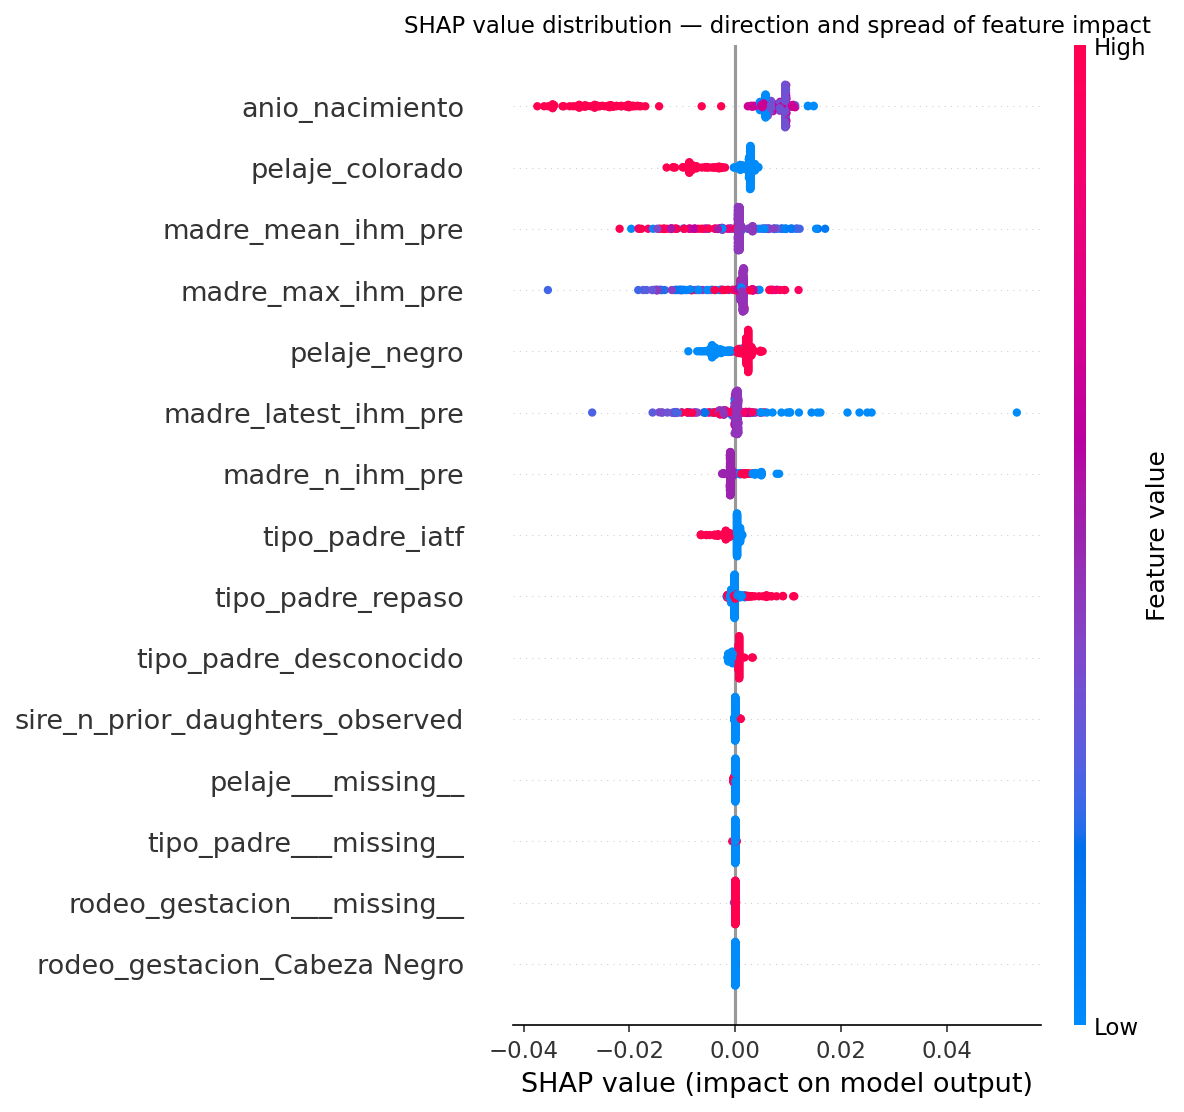

In [31]:
display(Image(filename='outputs/figures/10_shap_beeswarm.png'))

### Reading the SHAP plots

**`anio_nacimiento` dominates the importance ranking.** Birth year contributes more to the model's output than any other feature, by a factor of roughly 3× over the next-strongest feature. This is not biologically meaningful: birth year cannot in itself make a cow more or less productive. What `anio_nacimiento` actually captures is the IHM measurement-regime shift (raw weaning weight before 2024, 205-day-adjusted afterward). The model has learned this as a confound. The feature is retained in the headline results to be transparent about its impact, but it must be read as a methodology proxy, not a biological signal. It is the same feature that drove the temporal-holdout negative R² (§8.4) and the Layer 3 distribution-shift limitation (§10).

**Maternal IHM features cluster as the next-strongest signal.** `madre_max_ihm_pre`, `madre_mean_ihm_pre`, and `madre_latest_ihm_pre` all sit at comparable mean-|SHAP| values just below the cohort proxy and coat colour. This is the biologically grounded signal the project set out to find: heifers from mothers with higher historical IHM are predicted to be more productive themselves, and the beeswarm direction confirms the effect is positive and consistent. The three maternal features carry similar weight because they are correlated — the model is essentially using "the mother's productivity history" as a single latent variable expressed through three correlated columns.

**Coat colour carries meaningful weight.** Both `pelaje_colorado` and `pelaje_negro` appear in the top features. This is informative rather than spurious: the farm runs distinct black and red rodeos with somewhat different management histories, and the model picks up that the red-coat rodeo has tracked slightly differently on IHM. A real structural signal, not a biological one.

**Sire features contribute less than expected.** `sire_n_prior_daughters_observed` and `tipo_padre_iatf` appear lower in the ranking than the maternal features. This is partly a function of data availability: many sires have only one or two observed daughters by the time their next daughter is being evaluated, which limits the leakage-safe sire average to a noisy estimate. With more years of data, sire effects would likely rise.

**What is not there is also informative.** `peso_al_nacer` does not appear because it was dropped pre-modeling (constant placeholder, §5.6). Rodeo-of-gestation features appear near the bottom, suggesting that once mother and sire identity are accounted for, rodeo adds little marginal information.

**Takeaway for the rule.** SHAP confirms that the model is using a small, mostly biologically coherent set of features: maternal IHM history, coat/rodeo structure, and sire identity, with a known methodology confound on top. None of these contradict the farm's documented rule, which already uses mother IHM and sire type. The model's added value over the rule comes from *combining* these features continuously and from *ranking within* the rule's discrete tiers, not from discovering a new selection signal the farm doesn't already know about. If the farm were to add one feature to the written rule based on what the model uses, it would be the multi-year mother-IHM history (max or mean across years), not just the most recent year, since `madre_max_ihm_pre` ranks above `madre_latest_ihm_pre` in SHAP importance.

## 12. Failure cases

Where does this model make its largest errors?

In [32]:
residuals_path = Path('outputs/tables/largest_residuals.csv')
if residuals_path.exists():
    worst = pd.read_csv(residuals_path)
    print('Top 10 largest absolute residuals:')
    print(worst.head(10).to_string(index=False))

Top 10 largest absolute residuals:
      idv  anio_nacimiento   pelaje  tipo_padre  madre_mean_ihm_pre  mean_future_ihm  predicted_ihm  residual  n_outcome_years
BE099J100           2021.0    negro        iatf            0.446640         0.170000       0.388136 -0.218136              1.0
BE099J480           2021.0    negro      repaso            0.405405         0.550000       0.387378  0.162622              2.0
BE099K180           2022.0    negro      repaso                 NaN         0.220000       0.382263 -0.162263              1.0
BE099H956           2019.0    negro         NaN                 NaN         0.559119       0.408362  0.150758              3.0
BE099M752           2019.0    negro desconocido                 NaN         0.560000       0.411740  0.148260              1.0
BE099K271           2022.0    negro      repaso                 NaN         0.500000       0.356629  0.143371              1.0
BE099K150           2022.0    negro      repaso            0.465385         

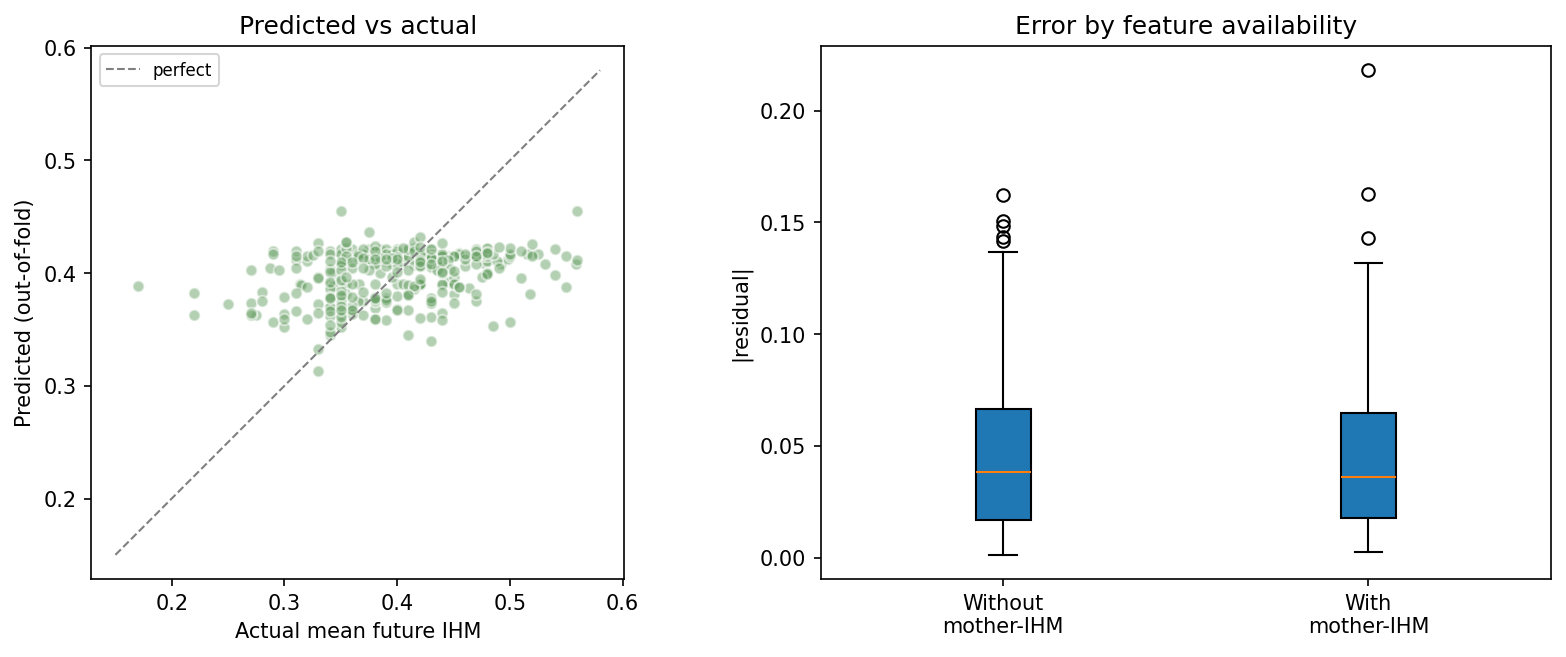

In [33]:
display(Image(filename='outputs/figures/11_residual_diagnostics.png'))

The largest prediction errors tend to occur for cows with only one or two recorded adult IHM observations. In these cases, the target variable itself is noisier, since the estimated long-term productivity is based on very limited reproductive history. Because IHM can vary substantially across calving events within the same cow, outcomes derived from only a small number of observations are inherently less stable and therefore more difficult for the model to predict accurately.

From an operational perspective, the model’s predictions should be treated as decision-support signals rather than ground truth. The model performs best at distinguishing clearly high-performing and clearly low-performing animals, while predictions for intermediate cases remain substantially more uncertain.

## 13. Conclusions

This project evaluated whether a data-driven model can refine the farm's hand-coded rule for replacement-heifer selection by formalising the existing rule system (not replacing it), identifying where expert judgment is still implicit, and testing whether data-driven ranking can improve selection quality.

**Main findings**

1. The documented rule reproduces only about 49% of the farm's actual decisions on a strict per-label match. The top tier (`verdes_3`) is perfectly reproduced. The lower tiers depend on unwritten criteria including a confirmed but undocumented *madre CUT* bonus. The decision system is partially codified: extremes explicit, middle running on experience-based judgment.

2. The IHM input evolved from raw weaning weight to 205-day-adjusted weight in newer records. The weight threshold (190 kg) has not changed. The methodological improvement is already reflected in the processed files.

3. Tree-based machine learning models achieve modest but consistent improvements over heuristic selection rules. At default hyperparameters, Random Forest leads on ranking metrics (precision@30% = 0.436). After tuning, Gradient Boosting achieves the strongest mean CV R² (0.101 ± 0.065) and the lowest variance (±0.065 vs ±0.084 for Random Forest); the two models are operationally comparable. Spearman ρ values fall between approximately 0.29 and 0.32 across tree-based models.

4. IHM and reproductive consistency are weakly anti-correlated (r = −0.15, p = 0.008, n = 309). Productivity has at least two genuinely separate dimensions, and the farm's current rule does not directly address reproductive consistency.

5. Reproductive consistency is substantially harder to predict from selection-time features than IHM (best ρ ≈ 0.25 vs ≈ 0.32), and the best model for pregnancy rate is linear/ridge regression rather than a tree ensemble, suggesting the reproductive signal is mostly additive in the available features while the IHM signal involves interaction effects.

**What surprised us**

Three findings were genuinely unexpected and shaped how we interpret the rest of the project.

First, the IHM–pregnancy correlation was *negative*, not positive. We assumed the two productivity dimensions would move together. The r = −0.15 correlation, although weak, is statistically significant (p = 0.008) and consistent in direction across cohorts. This pushed us toward the multi-target framing in §9 rather than treating IHM as a sufficient summary of productivity.

Second, the documented rule predicts `verdes_1` for *zero* of the 346 labelled heifers in the 2025 cohort. We expected the lower tiers to be approximated imperfectly, but a complete absence — when 58 cows are actually labelled `verdes_1` in the recorded data — was striking. It is also the clearest evidence that the system is only partially codified.

Third, `anio_nacimiento` dominated the SHAP importance ranking by roughly 3× over any biological feature. We set out to identify biologically grounded selection signals and instead found that the model's strongest lever is a methodology proxy — the IHM measurement regime shift. This forced us to read the rest of the SHAP plot as conditional on the cohort confound, and it is the same feature that drove the temporal-holdout negative R² and the Layer 3 distribution-shift limitation.

**Practical implications**

The value of machine learning in this setting is not replacing expert judgment with a black-box system. The primary contribution is making the existing rule system more explicit, measurable, and auditable. Three practical opportunities for the farm: formalising currently implicit decision criteria; documenting rule changes consistently across years; and using the model as a secondary ranking tool for borderline cases, currently the most subjective part of the selection process.

**What we would change if we did this again**

1. Request the complete DataMars export at the start. Because the export arrived late, reproductive features became a secondary analysis instead of the main modelling target.
2. Build the integrated notebook from the first stages instead of assembling it during the final week. Earlier integration would have caught issues like the constant `peso_al_nacer` weeks sooner.
3. Push earlier for digitised pre-2022 birth-weight records and cull data. Both the survivor bias issue and the loss of birth-weight information stem from historical paper records that were never fully digitised.
4. Plan the temporal split before feature engineering. Recognising earlier that birth year acted as a proxy for the measurement regime might have led us to engineer cohort-normalised features or report results separately by cohort.

**Limitations**

1. **Survivor bias.** Pre-2022 cull and sale records are unavailable; adult-IHM outcomes are observed only for cows that remained in the herd.
2. **Sparse maternal-IHM information.** For cows born before 2020, maternal IHM history is often incomplete. Approximately 60% of pre-2020 rows contain missing maternal-IHM features.
3. **Asymmetric reproductive outcomes.** 2020–2022 cohort outcomes were measured at *ecografía* (early pregnancy ultrasound), while 2023–2025 outcomes were measured at *tacto* (later palpation). Not fully equivalent.
4. **Small temporal holdout set.** 152 animals; should be interpreted as directional. Primary uncertainty estimates rely more heavily on 5-fold CV variance.
5. **Constant `peso_al_nacer`.** Older registry data records this as a constant 30 kg placeholder, removing what would likely have been one of the strongest selection-time features.
6. **Noisy target variable.** `mean_future_ihm` is averaged over a variable number of years (1–4 depending on the cow). Animals with fewer observations have less stable targets, limiting the maximum achievable predictive performance independent of model choice.

**Acknowledgements**

We would like to thank Matteo Turilli for all his help and guidance throughout the project, we definitely needed it and tried to take it into account throughout! Thanks to all of us for the support, eagerness, flexibility and dedication to the project, we did a great job! Thanks to Tatiana's uncle as well for giving us access to the farm's data, for helping us form the idea for the project and for the patience when we bombarded him with questions. Overall, we had a great time doing this project and hope it can become something somewhat useful to San Eduardo one day!